# Calculus

In [1]:
# Import NumPy and Matplotlib for this notebook.

import numpy as np
import matplotlib.pyplot as plt

## 중심차분법을 이용한 수치 미분

$f(x) = x^2$의 $x = 3$에서의 미분값을 중심차분법으로 근사한다.

$$f'(x) \approx \frac{f(x+h) - f(x-h)}{2h}$$

$h = 10^{-5}$로 계산하고, 해석적 미분값 $f'(3) = 2 \times 3 = 6$과의 절대 오차가 $10^{-4}$ 이하인지 확인한다.

In [2]:
# Define the quadratic function and numerical differentiation parameters.

# Evaluate f(x) = x^2.
def f(x):
    return x ** 2


x = 3.0
h = 1e-5

In [3]:
# Approximate the derivative using function values on both sides of x.

# The two evaluation points are 2h apart, so divide by 2h.
numerical_derivative = (f(x + h) - f(x - h)) / (2 * h)

In [4]:
# Compare with the analytical derivative and verify the absolute error.

analytical_derivative = 2 * x
absolute_error = abs(numerical_derivative - analytical_derivative)
tolerance = 1e-4

print(f"Central difference: {numerical_derivative:.12f}")
print(f"Analytical derivative: {analytical_derivative:.12f}")
print(f"Absolute error: {absolute_error:.3e}")
assert absolute_error <= tolerance, f"Absolute error exceeds {tolerance:.0e}."
print(f"Verified: absolute error <= {tolerance:.0e}")

Central difference: 6.000000000039
Analytical derivative: 6.000000000000
Absolute error: 3.931e-11
Verified: absolute error <= 1e-04


## 2변수 함수의 등고선

$f(x, y) = x^2 + y^2$를 $-3 \le x, y \le 3$ 범위에서 계산하고 등고선을 그린다.

함숫값이 양수 $c$인 등고선은 $x^2 + y^2 = c$이므로, 원점을 중심으로 반지름이 $\sqrt{c}$인 원이다. 각 등고선의 숫자와 색상 막대는 함숫값을 나타낸다.

In [5]:
# Create a two-dimensional grid of x and y coordinates.

x_values = np.linspace(-3, 3, 301)
y_values = np.linspace(-3, 3, 301)
# X and Y both have shape (301, 301), with one (x, y) pair per grid point.
X, Y = np.meshgrid(x_values, y_values)

In [6]:
# Evaluate f(x, y) = x^2 + y^2 at every grid point.

Z = X ** 2 + Y ** 2

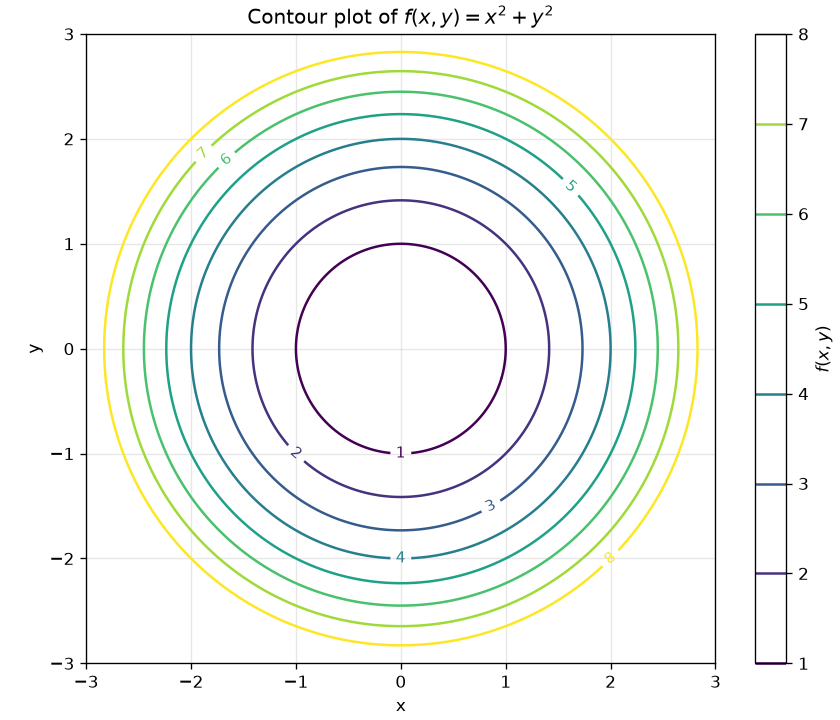

In [7]:
# Plot labeled contours and a color bar for the function values.

fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
contours = ax.contour(X, Y, Z, levels=np.arange(1, 9), cmap="viridis")
ax.clabel(contours, inline=True, fontsize=9, fmt="%g")
fig.colorbar(contours, ax=ax, label=r"$f(x, y)$")
# Equal axis scales preserve the circular shape of the level sets.
ax.set_aspect("equal")
ax.set(xlabel="x", ylabel="y", title=r"Contour plot of $f(x, y) = x^2 + y^2$")
ax.grid(True, alpha=0.3)
plt.show()

## Gradient와 등고선의 수직 관계

$f(x, y) = x^2 + y^2$의 Gradient는 $\nabla f = (2x, 2y)$이다. 등고선 $f = 1$과 $f = 4$ 위에서 각각 세 점을 선택하고, Gradient를 빨간 화살표로 표시한다. 화살표는 길이를 모두 같은 비율인 $1/5$로 줄여 그리며, 방향과 상대적인 크기는 유지한다.

각 점의 등고선 접선 방향은 $\mathbf{t} = (-y, x)$로 잡을 수 있다. $\nabla f \cdot \mathbf{t} = (2x)(-y) + (2y)x = 0$이므로 서로 수직이다. 점선으로 그린 접선과 직각 표시를 통해 이를 시각적으로 확인한다. 원점에서는 Gradient가 영벡터이므로 방향이 정의되지 않아 표본에서 제외한다.

In [8]:
# Select six points on the contours f = 1 and f = 4.

sample_angles = np.deg2rad([0, 120, 240, 60, 180, 300])
sample_radii = np.repeat([1.0, 2.0], 3)
# Each row of the (6, 2) array is a point (r cos(theta), r sin(theta)).
sample_points = np.column_stack((
    sample_radii * np.cos(sample_angles),
    sample_radii * np.sin(sample_angles),
))

In [9]:
# Compute gradients and contour tangents at the sample points.

gradients = 2 * sample_points
# Rotating the radial vector (x, y) by 90 degrees gives the tangent (-y, x).
tangents = np.column_stack((-sample_points[:, 1], sample_points[:, 0]))
# Unit vectors set the sizes of tangent segments and right-angle markers.
gradient_directions = gradients / np.linalg.norm(gradients, axis=1, keepdims=True)
tangent_directions = tangents / np.linalg.norm(tangents, axis=1, keepdims=True)

In [10]:
# Verify that each gradient is perpendicular to its contour tangent.

dot_products = np.sum(gradients * tangents, axis=1)
print("Gradient dot tangent:", dot_products)
assert np.allclose(dot_products, 0.0, atol=1e-12, rtol=0.0)

Gradient dot tangent: [0. 0. 0. 0. 0. 0.]


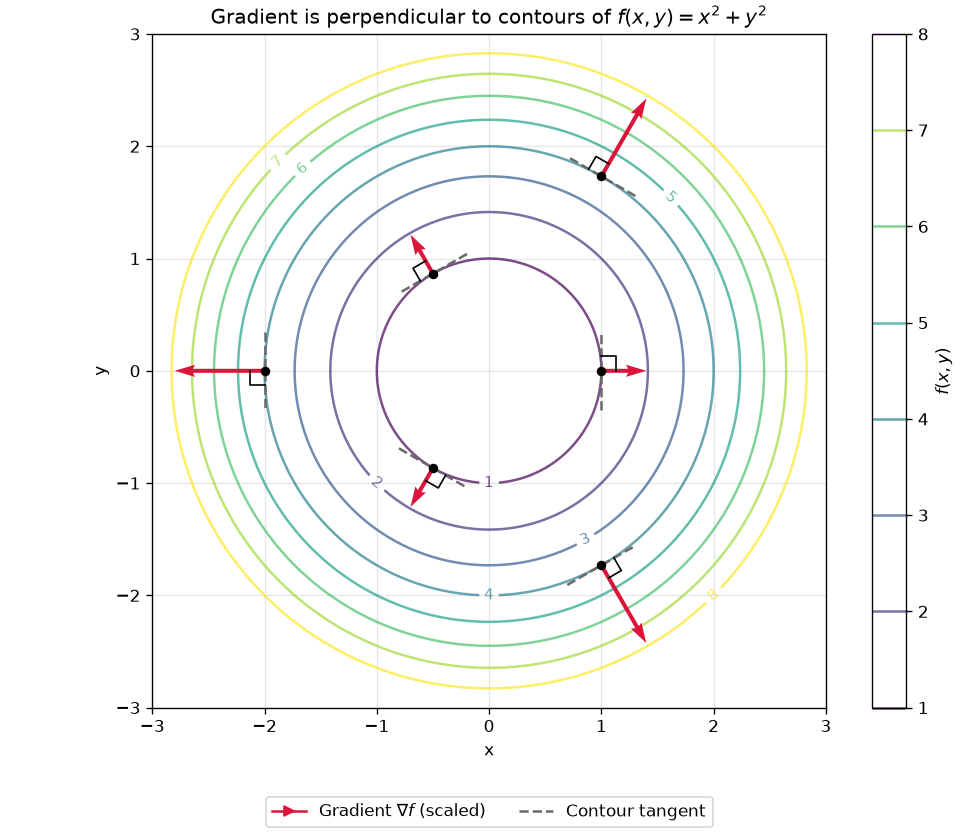

In [11]:
# Overlay gradient arrows, tangent segments, and right-angle markers on contours.

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
contours = ax.contour(X, Y, Z, levels=np.arange(1, 9), cmap="viridis", alpha=0.7)
ax.clabel(contours, inline=True, fontsize=9, fmt="%g")
fig.colorbar(contours, ax=ax, label=r"$f(x, y)$")
ax.scatter(*sample_points.T, color="black", s=22, zorder=4)
# Use data coordinates and one common scale: displayed arrows equal gradient / 5.
ax.quiver(
    *sample_points.T, *gradients.T,
    angles="xy", scale_units="xy", scale=5,
    color="crimson", width=0.006, zorder=3,
)
ax.plot([], [], color="crimson", marker=">", label=r"Gradient $\nabla f$ (scaled)")
for index, (point, normal, tangent) in enumerate(
    zip(sample_points, gradient_directions, tangent_directions)
):
    segment = point + np.array([-0.35, 0.35])[:, None] * tangent
    ax.plot(
        *segment.T, color="dimgray", linestyle="--", linewidth=1.5,
        label="Contour tangent" if index == 0 else None,
    )
    # The three corners form a right-angle marker between the two directions.
    corners = point + 0.13 * np.array([normal, normal + tangent, tangent])
    ax.plot(*corners.T, color="black", linewidth=1, zorder=5)
# Equal scales are required to display right angles without distortion.
ax.set_aspect("equal")
ax.set(
    xlim=(-3, 3), ylim=(-3, 3), xlabel="x", ylabel="y",
    title=r"Gradient is perpendicular to contours of $f(x, y) = x^2 + y^2$",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.grid(True, alpha=0.3)
plt.show()